# Práctico VAE (Variational AutoEncoders)

El objetivo de este práctico es explorar las Variational Autoencoders tanto en su implementación como sus bases teóricas.

In [1]:
#pip install torchinfo

In [2]:
import torch
import torchinfo
import numpy as np
import torch.nn as nn
from torch.optim import Adam
import matplotlib.pyplot as plt
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from mpl_toolkits.axes_grid1 import ImageGrid
from torchvision.utils import save_image, make_grid

### Dataset

In [3]:
# create a transform to apply to each datapoint
transform = transforms.ToTensor() #transforms.Compose([transforms.ToTensor()])

# download the MNIST datasets
path = './datasets'
train_dataset = MNIST(path, transform=transform, download=True)
test_dataset  = MNIST(path, train=False, transform=transform, download=True)

# create train and test dataloaders
batch_size = 100
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Running on {DEVICE}")

Running on mps


In [4]:
# get a batch of images
dataiter = iter(train_loader)
batch_images = next(dataiter)

In [5]:
batch_images[0].shape

torch.Size([100, 1, 28, 28])

In [6]:
# flatten batch
flatten_batch = batch_images[0].view(batch_size, 1*28*28).to(DEVICE)
flatten_batch.shape

torch.Size([100, 784])

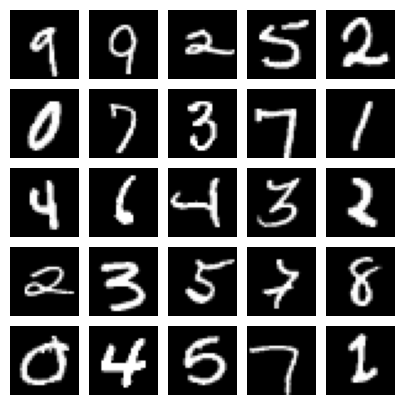

In [7]:
# get 25 sample training images for visualization
num_samples = 25
sample_images = [batch_images[0][i,0] for i in range(num_samples)]

fig = plt.figure(figsize=(5, 5))
grid = ImageGrid(fig, 111, nrows_ncols=(5, 5), axes_pad=0.1)

for ax, im in zip(grid, sample_images):
    ax.imshow(im, cmap='gray')
    ax.axis('off')

plt.show()

### Modelo VAE

In [8]:
import select
from numpy._core import fromnumeric
from matplotlib import transforms
class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, hidden_dim2=200, latent_dim=2, device='cpu'):
        # hidden_dim y hidden_dim2 son anchos de capas ocultas.
        # latent_dim es la dimension real del espacio latente (la de z).
        super(VAE, self).__init__()

        self.latent_dim = latent_dim

        self.device = device

        # TODO: Completar esta sección. Definir las capas de la VAE.
        # encoder:
        "Comprime imagen de 784 a 200 valores (aún no estamos en espacio latente). ReLu agrega no-linealidad "
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),    # 784 -> 400
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim2),  # 400 -> 200
            nn.ReLU(),
        )

        # latent mean and variance
        "Ambas funciones reciben mismo vector de 200 y devuelven 2 numeros, uno por dimensión latente."
        self.mean_layer = nn.Linear(hidden_dim2, latent_dim)   # 200 -> 2, Indica dónde etá centrada la gaussiana en el espacio latente
        self.logvar_layer = nn.Linear(hidden_dim2, latent_dim) # 200 -> 2, Se calcula Log de variana ya que capa Lineal puede devolver cualquier calor real (ej: negativos)

        # decoder
        "En ultima capa usamos Sigmoid ya que ToTensor deja pixeles en rango [0,1] y esto fuerza salida en ese rango"
        "Tambien permite usar Binary Cross Entropy (BCE) como función de pérdida"
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim2),     # 2 -> 200
            nn.ReLU(),
            nn.Linear(hidden_dim2, hidden_dim),     # 200 -> 400
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),       # 400 -> 784
            nn.Sigmoid(),
        )

    def encode(self, x):
        # TODO: Completar esta sección. Debes codificar 'x' usando la capa encoder
        # computar la media y la varianza de la distribución latente.
        # Devuelve la media y varianza
        h = self.encoder(x)                 # (batch, 784) -> (batch, 200), representación oculta (aún no es espacio latente)
        mean = self.mean_layer(h)           # (batch, 200) -> (batch, 2)
        logvar = self.logvar_layer(h)       # (batch, 200) -> (batch, 2)
        return mean, logvar

    def reparameterization(self, mean, logvar):
        # TODO: Completar esta sección. Aplica el truco de reparametrización.
        # Devuelve 'z' luego de hacer el reparametrization trick.
        # z = mu + sigma * eps ~ N(0, I)
        # El azar queda en eps (no depende de parámetros), así gradiente fluye por mean y logvar 
        std = torch.exp(0.5 * logvar)   # sigma = exp(log(sigma^2) / 2), siempre > 0
        eps = torch.randn_like(std)     # mismo shape y device que std: (batch, latent_dim)
        z = mean + std * eps            # (batch, 2)
        return z 

    def decode(self, z):
        # TODO: Completar esta sección. Usar el decodificador para transformar 'z' 
        #      de nuevo a una representación del espacio original.
        # Devuelve la reconstrucción.
        # (batch, 2) -> (batch, 784), pixeles en [0, 1] por sigmoid
        return self.decoder(z)

    def forward(self, x):
        # TODO: Completar esta sección. Sigue el flujo de la VAE:
        # 1. Codificar
        # 2. Reparametrizar
        # 3. Decodificar
        # Devuelve la reconstrucción, la media y la varianza.
        mean, logvar = self.encode(x)               # 1. (batch, 784) -> (batch, 2), (batch, 2)
        z = self.reparameterization(mean, logvar)   # 2. muestreo derivable: z = mu + sigma * eps
        x_hat = self.decode(z)                      # 3. (batch, 2) -> (batch, 784)
        return x_hat, mean, logvar                  # Reconstruccion usa x y x_hat, KL usa mean y logvar (sin esto no se puede calcular KL y sería un autoencoder común)
    
    def generate(self, num_samples=1):
        # TODO: Completar esta sección. Generar nuevas muestras a partir de la distribución latente.
        # Devuelve las nuevas muestras generadas.
        # Muestreamos x del prior p(z) = N(0, I) y lo decodificamos (no se usa el encoder)
        with torch.no_grad():                                                   # inferencia: no hace falta grafo de gradientes
            z = torch.randn(num_samples, self.latent_dim, device=self.device)   # (num_samples, 2)
            samples = self.decode(z)                                            # (num_samples, 784)
        return samples

In [9]:
LR = 1e-3

model = VAE(device=DEVICE).to(DEVICE)
optimizer = Adam(model.parameters(), lr=LR)

In [10]:
torchinfo.summary(model, input_size=(100,784), col_names = ('input_size', 'output_size', 'num_params'))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
VAE                                      [100, 784]                [100, 784]                --
├─Sequential: 1-1                        [100, 784]                [100, 200]                --
│    └─Linear: 2-1                       [100, 784]                [100, 400]                314,000
│    └─ReLU: 2-2                         [100, 400]                [100, 400]                --
│    └─Linear: 2-3                       [100, 400]                [100, 200]                80,200
│    └─ReLU: 2-4                         [100, 200]                [100, 200]                --
├─Linear: 1-2                            [100, 200]                [100, 2]                  402
├─Linear: 1-3                            [100, 200]                [100, 2]                  402
├─Sequential: 1-4                        [100, 2]                  [100, 784]                --
│    └─Linear: 2-5      

###  Función de Pérdida

In [11]:
def loss_function(x, x_hat, mean, log_var):
    # TODO: Completar esta sección. Implementar la función de pérdida de la VAE.
    # 1) Calcule la pérdida de reconstrucción (reconstruction loss) entre x y x_hat.
    # Reconstrucción: BCE pixel a pixel entre la imagen original y la reconstruida.
    reproduction_loss = nn.functional.binary_cross_entropy(x_hat, x, reduction='sum') # "sum" para que este en misma escala que KLD
    # 2) Calcule la divergencia KL (Kullback-Leibler divergence) entre la distribución latente y una distribución normal estándar.
    KLD = - 0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp())
    # 3) Devuelva la pérdida.
    return reproduction_loss + KLD

### Entrenamiento

In [12]:
def train(model, optimizer, epochs, device, x_dim=784):
    model.train()
    for epoch in range(epochs):
        overall_loss = 0
        for x, _ in train_loader:
            x = x.view(x.size(0), x_dim).to(device)

            optimizer.zero_grad()

            x_hat, mean, log_var = model(x)
            loss = loss_function(x, x_hat, mean, log_var)

            overall_loss += loss.item()

            loss.backward()
            optimizer.step()

        print("\tEpoch", epoch + 1, "\tAverage Loss: ", overall_loss/len(train_loader.dataset))
    return overall_loss

In [13]:
train(model.to(DEVICE), optimizer, epochs=10, device=DEVICE)

	Epoch 1 	Average Loss:  182.2554349609375
	Epoch 2 	Average Loss:  159.57069480794271
	Epoch 3 	Average Loss:  154.74692333984376
	Epoch 4 	Average Loss:  151.7424023763021
	Epoch 5 	Average Loss:  149.86493746744793
	Epoch 6 	Average Loss:  148.07390467122397
	Epoch 7 	Average Loss:  147.0613121419271
	Epoch 8 	Average Loss:  146.16473445638022
	Epoch 9 	Average Loss:  145.2547919596354
	Epoch 10 	Average Loss:  144.84091479492187


8690454.887695312

### Generación

In [14]:
def generate_digit(model, z=None):
    # Si z es None, muestreamos del prior p(z) = N(0, I).
    # Si se pasa un z, decodificamos ese punto concreto del espacio latente.
    if z is None:
        x_decoded = model.generate()
    else:
        z = torch.tensor([z], dtype=torch.float).to(DEVICE)
        x_decoded = model.decode(z)
        plt.title(f'z = {z.tolist()[0]}')

    digit = x_decoded.detach().cpu().reshape(28, 28)
    plt.imshow(digit, cmap='gray')
    plt.axis('off')
    plt.show()

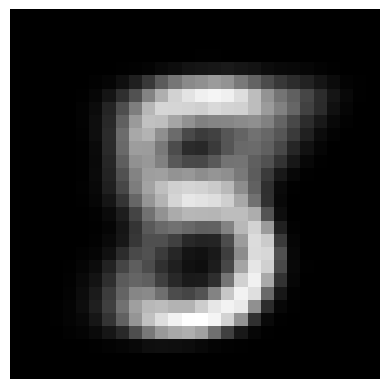

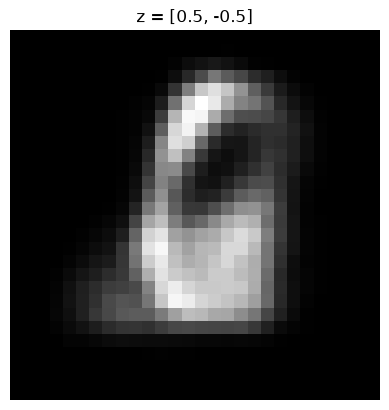

In [15]:
generate_digit(model)               # muestra aleatoria del prior
generate_digit(model, [0.5, -0.5])  # punto concreto del espacio latente

### Mostrar el espacio latente

In [16]:
def plot_latent_space(model, scale=5.0, n=25, digit_size=28, figsize=15, title='VAE Latent Space Viz'):
    # display a n*n 2D manifold of digits
    figure = np.zeros((digit_size * n, digit_size * n))

    # construct a grid
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_sample = torch.tensor([[xi, yi]], dtype=torch.float).to(DEVICE)
            x_decoded = model.decode(z_sample)
            digit = x_decoded[0].detach().cpu().reshape(digit_size, digit_size)
            figure[i * digit_size : (i + 1) * digit_size, j * digit_size : (j + 1) * digit_size,] = digit

    plt.figure(figsize=(figsize, figsize))
    plt.title(title)
    start_range = digit_size // 2
    end_range = n * digit_size + start_range
    pixel_range = np.arange(start_range, end_range, digit_size)
    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)
    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.imshow(figure, cmap="Greys_r")
    plt.show()

Es interesante observar en este mapa continuo del espacio latente:

- Al moverse hacia la derecha, las imágenes pasan gradualmente de unos dígitos a otros: aparecen zonas con 1, 9, 8, 2, 6 y 0.

- Al moverse hacia arriba o abajo, cambia el estilo o la forma de los dígitos. Por ejemplo, algunos 1 se inclinan y varios 7 o 9 cambian de trazo.

- Entre las zonas donde predominan dos dígitos hay imágenes borrosas o ambiguas. Son transiciones del decoder entre regiones del espacio latente.

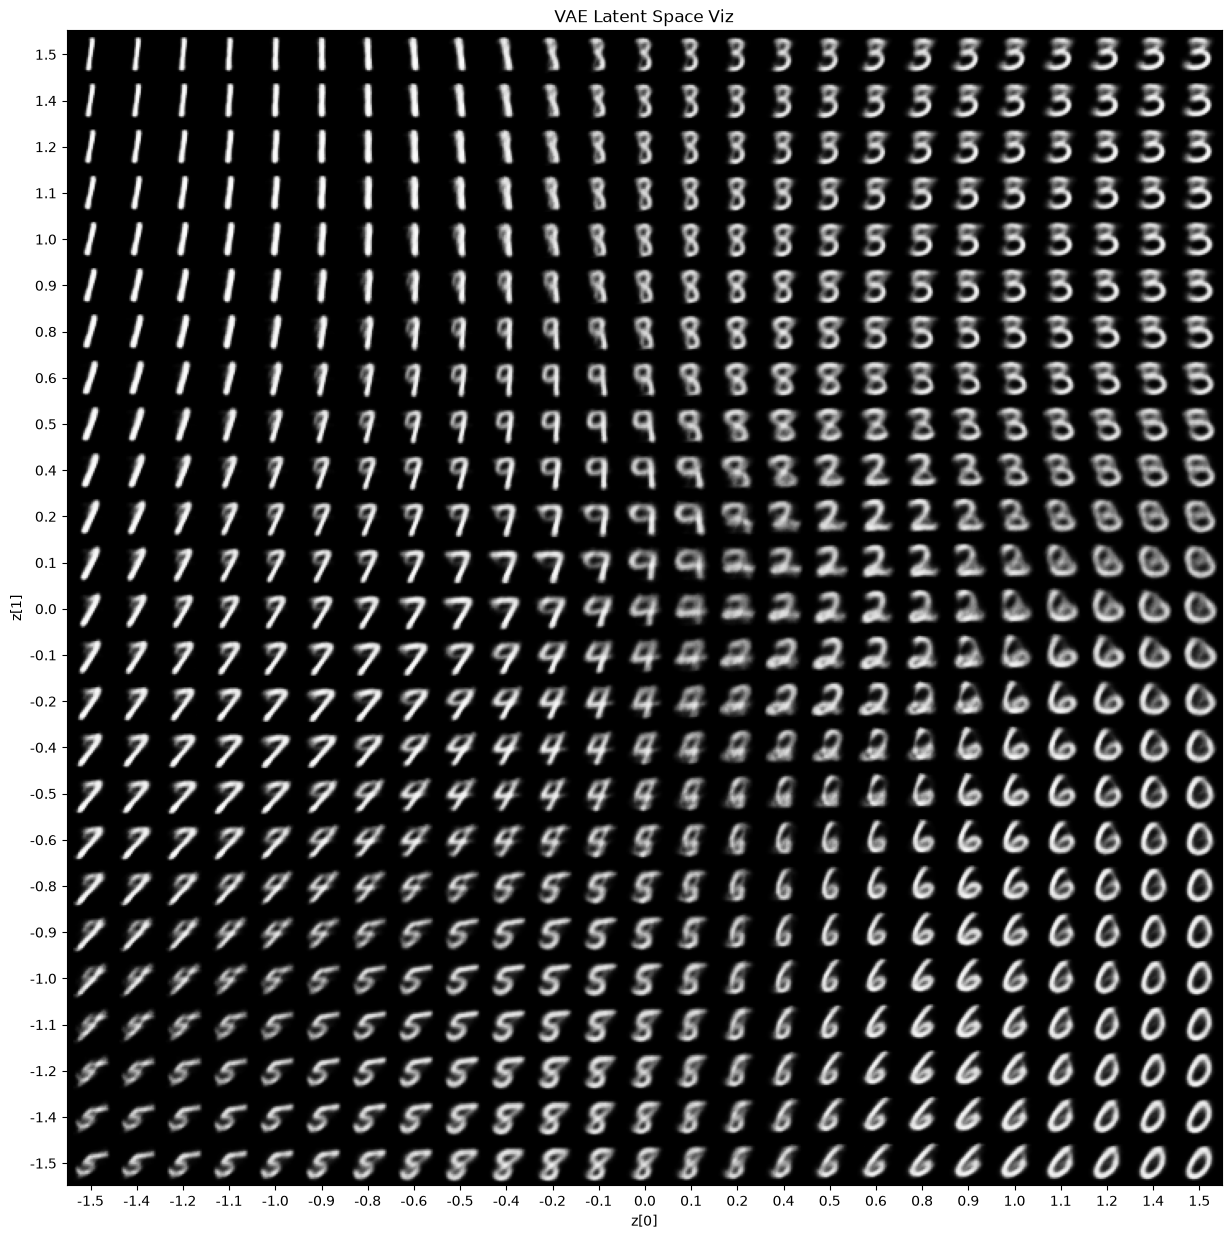

In [17]:
plot_latent_space(model, scale=1.5)

## Ejercicios

1. Complete el código.
2. ¿Por qué es necesario el truco de reparametrización en las VAE?

Para entrenar la VAE con backpropagation, necesitamos que el gradiente de la pérdida pueda propagarse desde el decoder hasta el encoder. El encoder no devuelve un valor fijo de $z$, sino los parámetros $\mu$ y $\sigma^2$ de una distribución latente. Si muestreamos $z$ directamente de esa distribución, la operación aleatoria dificulta calcular el gradiente respecto de $\mu$ y $\sigma$. El truco de reparametrización expresa el muestreo como $z = \mu + \sigma \odot \epsilon$, donde $\epsilon \sim \mathcal{N}(0, I)$. Así, el azar queda en $\epsilon$, independiente del encoder, y $z$ es diferenciable respecto de $\mu$ y $\sigma$.

3. ¿Qué representan las variables mean y var en la VAE?


Aquí se marca una diferencia clave con un autoencoder común: la VAE representa cada imagen mediante una distribución gaussiana en el espacio latente, en lugar de asignarle un único punto. `mean` ($\mu$) indica el centro de esa distribución y `logvar` representa el logaritmo de su varianza.  Para muestrear un punto latente se usa $z = \mu + \sigma \odot \epsilon$, donde $\sigma = \exp\left(\frac{1}{2}\,\text{logvar}\right)$ y $\epsilon \sim \mathcal{N}(0, I)$. Así, el decoder recibe muestras cercanas a $\mu$; $\sigma$ controla cuánto pueden variar. Junto con la regularización KL, esto favorece un espacio latente continuo y organizado, donde puntos cercanos tienden a generar imágenes similares.


4. Cree y entrene nuevas VAE modificando los hiperparámetros.

La función `loss_function_beta` calcula la pérdida de reconstrucción ($\text{rec}$) y la divergencia KL ($\text{kld}$) entre la distribución latente que el encoder predice para cada imagen y el prior $\mathcal{N}(0, I)$. La pérdida total es $\text{rec} + \text{beta} * \text{kld}$. El parámetro $\beta$ controla cuánto se penaliza que esas distribuciones latentes se alejen del prior.
Con $\beta = 1$ se usa la ponderación habitual de la VAE; al variarlo, se explora el equilibrio entre reconstrucción y regularización.

In [18]:
def loss_function_beta(x, x_hat, mean, log_var, beta=1.0):
    rec = nn.functional.binary_cross_entropy(x_hat, x, reduction='sum')
    kld = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp())
    return rec, kld, rec + beta * kld

La función `run_experiment` crea y entrena una VAE con la configuración indicada —dimensión latente, tamaños de capas, learning rate, épocas y beta— usando los datos de entrenamiento. Fija semillas para hacer reproducibles la inicialización y el orden de los batches. Durante cada época registra, como promedio por imagen, la pérdida de reconstrucción (BCE), la divergencia KL y la pérdida total ponderada por beta. Al final devuelve el modelo entrenado, el historial de pérdidas y el valor de beta usado.

In [24]:
def run_experiment(
    name,
    latent_dim=2,
    hidden_dim=400,
    hidden_dim2=200,
    lr=1e-3,
    epochs=10,
    beta=1.0,
    seed=0,
):
    # Misma semilla de inicialización para facilitar la comparación
    torch.manual_seed(seed)

    model = VAE(
        hidden_dim=hidden_dim,
        hidden_dim2=hidden_dim2,
        latent_dim=latent_dim,
        device=DEVICE,
    ).to(DEVICE)

    optimizer = Adam(model.parameters(), lr=lr)

    # Cada experimento usa el mismo orden de batches
    experiment_loader = DataLoader(
        dataset=train_dataset,
        batch_size=train_loader.batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    history = {
        "rec": [],
        "kld": [],
        "loss": [],
    }

    num_images = len(train_dataset)

    for epoch in range(epochs):
        model.train()

        total_rec = 0.0
        total_kld = 0.0
        total_loss = 0.0

        for x, _ in experiment_loader:
            x = x.view(x.size(0), 784).to(DEVICE)

            optimizer.zero_grad()

            x_hat, mean, log_var = model(x)
            rec, kld, loss = loss_function_beta(
                x, x_hat, mean, log_var, beta=beta
            )

            loss.backward()
            optimizer.step()

            # BCE y KL están sumados sobre el batch.
            total_rec += rec.item()
            total_kld += kld.item()
            total_loss += loss.item()

        # Promedio por imagen para poder interpretar los valores.
        history["rec"].append(total_rec / num_images)
        history["kld"].append(total_kld / num_images)
        history["loss"].append(total_loss / num_images)

        print(
            f"{name:10s} | Época {epoch + 1:2d}/{epochs} "
            f"| BCE/img: {history['rec'][-1]:6.1f} "
            f"| KL/img: {history['kld'][-1]:5.1f} "
            f"| Objetivo/img (beta={beta}): {history['loss'][-1]:6.1f}"
        )

    return {
        "model": model,
        "history": history,
        "beta": beta,
    }

In [25]:
configs = {
    "base":      dict(),
    "latent_10": dict(latent_dim=10),
    "latent_20": dict(latent_dim=20),
    "small_net": dict(hidden_dim=128, hidden_dim2=64),
    "lr_1e-2":   dict(lr=1e-2),
    "lr_1e-4":   dict(lr=1e-4),
    "beta_0.5":  dict(beta=0.5),
    "beta_4":    dict(beta=4.0),
}

results = {
    name: run_experiment(name, **config)
    for name, config in configs.items()
}

base       | Época  1/10 | BCE/img:  178.8 | KL/img:   3.9 | Objetivo/img (beta=1.0):  182.7
base       | Época  2/10 | BCE/img:  156.0 | KL/img:   5.2 | Objetivo/img (beta=1.0):  161.2
base       | Época  3/10 | BCE/img:  149.1 | KL/img:   5.6 | Objetivo/img (beta=1.0):  154.7
base       | Época  4/10 | BCE/img:  145.5 | KL/img:   5.9 | Objetivo/img (beta=1.0):  151.4
base       | Época  5/10 | BCE/img:  142.9 | KL/img:   6.1 | Objetivo/img (beta=1.0):  149.0
base       | Época  6/10 | BCE/img:  141.1 | KL/img:   6.2 | Objetivo/img (beta=1.0):  147.3
base       | Época  7/10 | BCE/img:  139.6 | KL/img:   6.3 | Objetivo/img (beta=1.0):  145.9
base       | Época  8/10 | BCE/img:  138.6 | KL/img:   6.3 | Objetivo/img (beta=1.0):  145.0
base       | Época  9/10 | BCE/img:  137.9 | KL/img:   6.4 | Objetivo/img (beta=1.0):  144.3
base       | Época 10/10 | BCE/img:  137.0 | KL/img:   6.5 | Objetivo/img (beta=1.0):  143.5
latent_10  | Época  1/10 | BCE/img:  160.5 | KL/img:   8.4 | Objetivo/

- **Dimensión latente 10 y 20:** sus curvas de BCE caen mucho más que la del modelo base, y terminan cerca de 85. El KL sube hasta alrededor de 18, señal de que el encoder se aleja más del prior para representar información útil para reconstruir. En este experimento, pasar de 10 a 20 dimensiones aporta poco: ambas curvas quedan casi superpuestas.
  
- **Red pequeña (small_net):** termina con BCE y objetivo más altos que el modelo base. Con esta arquitectura y estas 10 épocas, reconstruye peor.

- **Learning rate:** con 1e-2, la BCE casi no mejora; parece demasiado alto para esta configuración. Con 1e-4, baja de manera sostenida, pero termina por encima de la del modelo base; podría necesitar más épocas.

- **beta=0.5 y beta=4:** con beta=0.5, la BCE termina más baja y el KL más alto que con beta=4. Eso concuerda con el peso menor sobre la regularización. Con beta=4, el KL es menor, pero la reconstrucción termina peor.

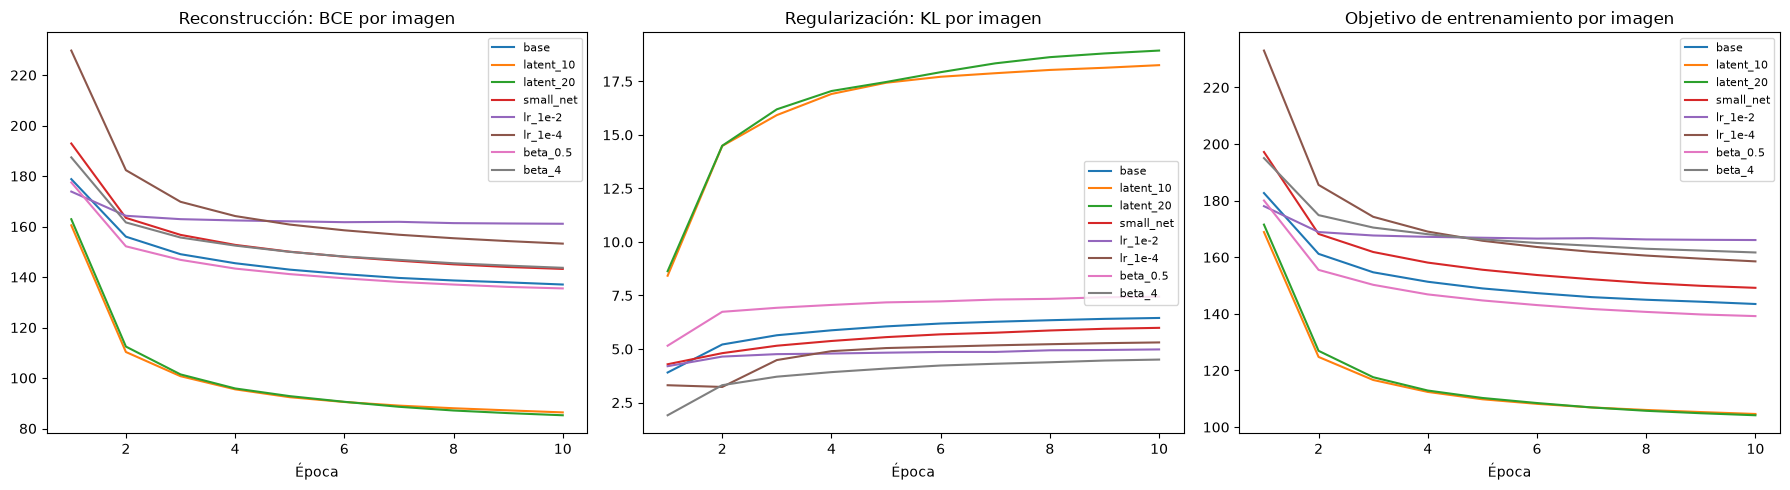

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for name, result in results.items():
    history = result["history"]
    epochs_range = range(1, len(history["rec"]) + 1)

    axes[0].plot(epochs_range, history["rec"], label=name)
    axes[1].plot(epochs_range, history["kld"], label=name)
    axes[2].plot(epochs_range, history["loss"], label=name)

axes[0].set_title("Reconstrucción: BCE por imagen")
axes[1].set_title("Regularización: KL por imagen")
axes[2].set_title("Objetivo de entrenamiento por imagen")

for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

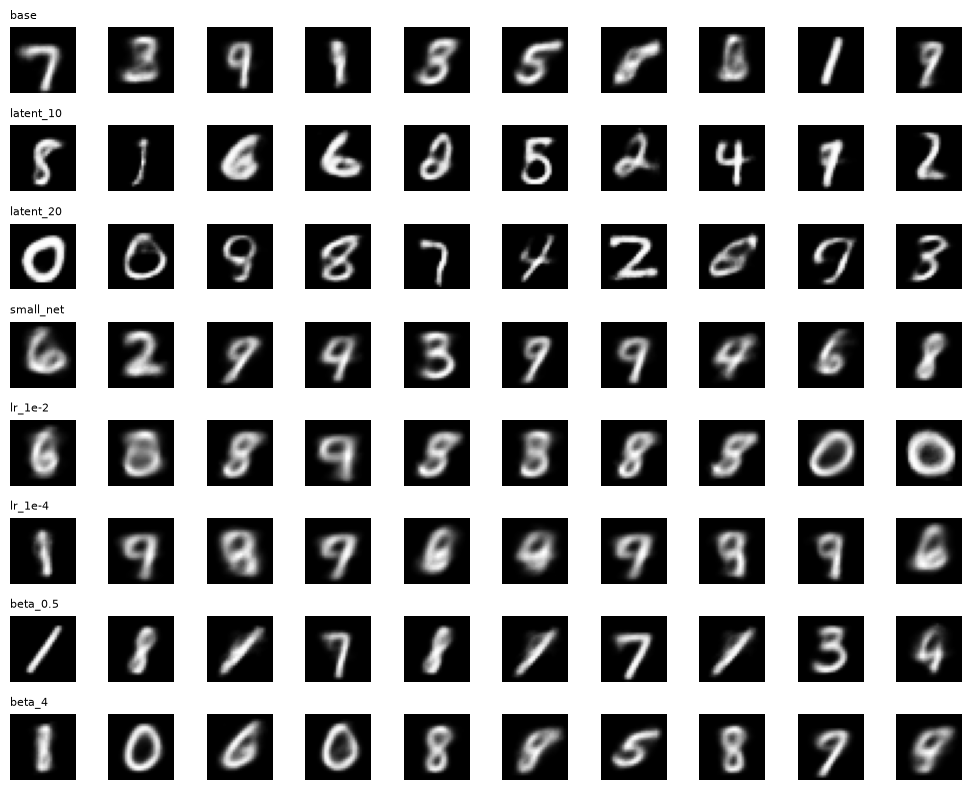

In [30]:
# Muestras generadas por modelo (cada fila es un modelo):
fig, axes = plt.subplots(len(results), 10, figsize=(10, len(results)))
for row, (name, r) in enumerate(results.items()):
    samples = r['model'].generate(10).cpu().view(-1, 28, 28)
    for col in range(10):
        axes[row, col].imshow(samples[col], cmap='gray')
        axes[row, col].axis('off')
    axes[row, 0].set_title(name, fontsize=8, loc='left')
plt.tight_layout(); plt.show()

5. ¿Cómo afecta la elección del tamaño del espacio latente al rendimiento de la VAE?


Al subir la dimensión latente a 10 y 20 se observa una mejora global en la loss, producto de tener curvas de BCE mucho más bajas que la del modelo base (dimensión latente 2). No obstante, se observa que para las dimensiones 10 y 20 la KL sube hasta alrededor de 18, señal de que el encoder se aleja más del prior para representar información útil para reconstruir. 

Vemos también que menor perdida no implica mejor generación, ya que el latente 2 produce digitos borrosos pero casi siempre reconocibles. Los modelos con 10 y 20 generan imagenes con trazos más nitidos y variados, pero también con varias muestras deformes que no corresponden a ningún dígito (peor en latente 20). 


6. ¿Qué rol juega el término de regularización KL-divergence en la función de pérdida de la VAE?


KL mide la distancia entre distribución de imagen real contra la asignada por el encoder, que a su vez actúa como regularizador ya que penaliza medias alejadas del origen y varianzas que puedan llegar a colapsar. Esto hace que cada imagen ocupe una región dentro del espacio latente. Es necesario KL sino VAE sería un autoencoder determinista, con espacio latente irregular que no se podría muestrear. 

7. Explique que ve en la imágen que se genera cuando llamamos a la función `plot_latent_space`. Si cambiamos la dimensión del espacio latente, ¿qué pasaría con esta gráfica?

La grilla muestra un mapa continuo del espacio latente: cada posición $\text{(z[0], z[1])}$ se decodifica en una imagen. Lo que muestra es cómo el modelo genera imagenes en cada región del espacio latente. Si se cambia la dimensión del espacio latente, cambia cómo se genera este mapeo. Por ejemplo, si cambiamos a una sola dimensión el mapa pasaría a ser una tira donde los dígitos deben ordenarse sobre esa misma linea. Si aumentamos a más de dos no se podría representar en un espacio 2D. 